In [26]:
!pip install -q pandas matplotlib scipy requests

Saved islamabad_temperature_history_2026.png and islamabad_temperature_history_2026.xlsx


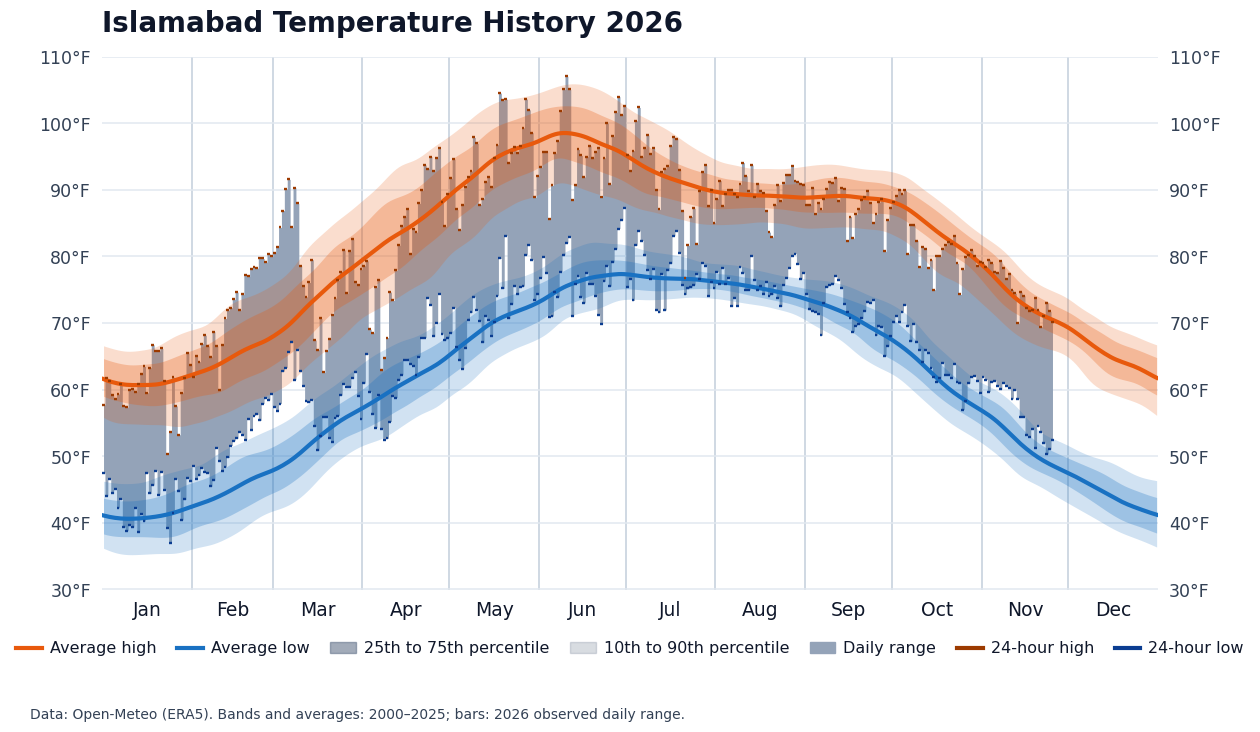

In [29]:
"""
Temperature History chart + Excel export for any city.

1. Edit the CONFIG block below (city, coordinates, colours).
2. Run:  python temperature_history.py
   -> islamabad_temperature_history_<year>.png   (high-res chart)
   -> islamabad_temperature_history_<year>.xlsx  (all data used in the chart)

pip install requests pandas numpy matplotlib scipy openpyxl
"""
import datetime as dt

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from scipy.ndimage import gaussian_filter1d

# ═════════════════════════ CONFIG ═════════════════════════
CITY = "Islamabad"
LAT, LON = 33.6844, 73.0479
TIMEZONE = "Asia/Karachi"
CLIM_FROM = 2000          # climatology uses CLIM_FROM … (this year - 1)
WINDOW_DAYS = 7           # percentiles use ±7 days around each day of the year
SMOOTH_DAYS = 3           # smoothing of the climatology curves
DPI = 200                 # PNG sharpness

TEXT = "#0F172A"          # titles and labels (near-black navy)
TEXT_SOFT = "#334155"     # axis tick labels
GRID = "#E2E8F0"
HIGH = "#E8590C"          # average high + its bands (vivid orange)
LOW = "#1971C2"           # average low + its bands (strong blue)
HIGH_DARK = "#9C3A00"     # 24-hour high ticks
LOW_DARK = "#0B3D91"      # 24-hour low ticks
BARS = "#94A3B8"          # observed daily range (slate)

# ═════════════════════════ DATA ═════════════════════════
ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
FORECAST = "https://api.open-meteo.com/v1/forecast"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH_START = np.cumsum([0, 31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])   # 0 … 365


def c2f(c):
    return np.asarray(c, float) * 9 / 5 + 32


def fetch_daily(url, **extra):
    """Daily high/low (°C) from Open-Meteo -> DataFrame[date, high_c, low_c]."""
    r = requests.get(url, timeout=120, params=dict(
        latitude=LAT, longitude=LON, timezone=TIMEZONE,
        daily="temperature_2m_max,temperature_2m_min", **extra))
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.DataFrame({"date": pd.to_datetime(d["time"]),
                         "high_c": d["temperature_2m_max"], "low_c": d["temperature_2m_min"]})


def fetch_history(year):
    return fetch_daily(ARCHIVE, start_date=f"{CLIM_FROM}-01-01", end_date=f"{year - 1}-12-31")


def fetch_observed(today):
    """This year's daily high/low up to yesterday (archive + forecast API for the last days)."""
    parts = []
    archive_end = today - dt.timedelta(days=6)
    if archive_end >= dt.date(today.year, 1, 1):
        parts.append(fetch_daily(ARCHIVE, start_date=f"{today.year}-01-01", end_date=archive_end.isoformat()))
    try:
        recent = fetch_daily(FORECAST, past_days=10, forecast_days=1)
        parts.append(recent[recent["date"] < pd.Timestamp(today)])
    except Exception as e:
        print("Could not fetch the most recent days:", e)
    df = pd.concat(parts).drop_duplicates("date").sort_values("date").dropna()
    return df[df["date"].dt.year == today.year]


def add_doy(df):
    """Add year + day-of-year (1..365, Feb 29 dropped)."""
    df = df[~((df["date"].dt.month == 2) & (df["date"].dt.day == 29))].copy()
    df["year"] = df["date"].dt.year
    df["doy"] = pd.to_datetime("2001-" + df["date"].dt.strftime("%m-%d")).dt.dayofyear
    return df


def climatology(history):
    """Average + 10/25/75/90th percentiles of daily highs and lows for each day of year (°C)."""
    out = pd.DataFrame(index=pd.Index(range(1, 366), name="doy"))
    for kind in ("high", "low"):
        m = history.pivot(index="year", columns="doy", values=f"{kind}_c").reindex(columns=range(1, 366)).values
        window = np.concatenate([np.roll(m, k, axis=1) for k in range(-WINDOW_DAYS, WINDOW_DAYS + 1)])
        p10, p25, p75, p90 = np.nanpercentile(window, [10, 25, 75, 90], axis=0)
        for name, values in (("avg", np.nanmean(window, 0)), ("p10", p10), ("p25", p25),
                             ("p75", p75), ("p90", p90)):
            out[f"{kind}_{name}"] = gaussian_filter1d(values, SMOOTH_DAYS, mode="wrap")
    return out


# ═════════════════════════ CHART ═════════════════════════
def draw(clim, obs, year):
    plt.rcParams.update({"font.size": 12.5, "axes.edgecolor": GRID})
    fig, ax = plt.subplots(figsize=(12, 7.4), facecolor="white")
    x = clim.index.values - 0.5                       # centre of each day

    # observed daily range (this year) + 24-hour high / low ticks
    ox = obs["doy"].values - 0.5
    ax.fill_between(ox, c2f(obs["low_c"]), c2f(obs["high_c"]), step="mid", color=BARS, lw=0, zorder=2)
    ax.hlines(c2f(obs["high_c"]), ox - 0.5, ox + 0.5, color=HIGH_DARK, lw=1.7, zorder=5)
    ax.hlines(c2f(obs["low_c"]), ox - 0.5, ox + 0.5, color=LOW_DARK, lw=1.7, zorder=5)

    # climatology: 10–90 and 25–75 percentile bands + average line
    for kind, color in (("high", HIGH), ("low", LOW)):
        ax.fill_between(x, c2f(clim[f"{kind}_p10"]), c2f(clim[f"{kind}_p90"]), color=color, alpha=0.20, lw=0, zorder=3)
        ax.fill_between(x, c2f(clim[f"{kind}_p25"]), c2f(clim[f"{kind}_p75"]), color=color, alpha=0.28, lw=0, zorder=3)
        ax.plot(x, c2f(clim[f"{kind}_avg"]), color=color, lw=3, zorder=4)

    # axes
    lo = c2f(min(clim["low_p10"].min(), obs["low_c"].min()))
    hi = c2f(max(clim["high_p90"].max(), obs["high_c"].max()))
    ax.set_ylim(10 * np.floor((lo - 2) / 10), 10 * np.ceil((hi + 2) / 10))
    ax.set_xlim(0, 365)
    ax.set_xticks((MONTH_START[:-1] + MONTH_START[1:]) / 2, MONTHS)
    ax.set_xticks(MONTH_START[1:-1], minor=True)
    ax.grid(axis="y", color=GRID, lw=1.1)
    ax.grid(axis="x", which="minor", color="#CBD5E1", lw=1.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", which="both", length=0, labelsize=13.5, labelcolor=TEXT, pad=8)
    ax.tick_params(axis="y", length=0, labelsize=12.5, labelcolor=TEXT_SOFT, labelright=True, pad=8)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}°F"))
    for s in ax.spines.values():
        s.set_visible(False)

    ax.set_title(f"{CITY} Temperature History {year}", loc="left", fontsize=20,
                 fontweight="bold", color=TEXT, pad=18)

    # legend
    handles = [
        Line2D([], [], color=HIGH, lw=3), Line2D([], [], color=LOW, lw=3),
        Patch(color="#64748B", alpha=0.6), Patch(color="#64748B", alpha=0.25), Patch(color=BARS),
        Line2D([], [], color=HIGH_DARK, lw=3), Line2D([], [], color=LOW_DARK, lw=3),
    ]
    labels = ["Average high", "Average low", "25th to 75th percentile", "10th to 90th percentile",
              "Daily range", "24-hour high", "24-hour low"]
    ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=7, frameon=False,
              fontsize=11.5, labelcolor=TEXT, handlelength=1.6, columnspacing=1.3, handletextpad=0.5)
    fig.text(0.0, -0.005, f"Data: Open-Meteo (ERA5). Bands and averages: {CLIM_FROM}–{year - 1}; "
             f"bars: {year} observed daily range.", fontsize=10, color=TEXT_SOFT)
    fig.subplots_adjust(left=0.06, right=0.94, top=0.89, bottom=0.17)
    return fig


# ═════════════════════════ EXCEL ═════════════════════════
LABELS = {"doy": "Day of year", "date": "Date", "high_c": "Daily high °C", "low_c": "Daily low °C",
          "high_avg": "Average high °C", "high_p10": "High 10th pct °C", "high_p25": "High 25th pct °C",
          "high_p75": "High 75th pct °C", "high_p90": "High 90th pct °C",
          "low_avg": "Average low °C", "low_p10": "Low 10th pct °C", "low_p25": "Low 25th pct °C",
          "low_p75": "Low 75th pct °C", "low_p90": "Low 90th pct °C"}


def excel_table(df, cols):
    """Rename columns and add a °F twin for every °C column."""
    t = df[cols].rename(columns=LABELS).round(2)
    for c in [c for c in t.columns if c.endswith("°C")]:
        t[c.replace("°C", "°F")] = c2f(t[c]).round(2)
    return t


def save_excel(path, clim, obs, history, year):
    clim = clim.reset_index()
    clim.insert(1, "date", (pd.Timestamp(2001, 1, 1) + pd.to_timedelta(clim["doy"] - 1, unit="D")).dt.strftime("%b %d"))
    sheets = {
        "Climatology": excel_table(clim, ["doy", "date"] + [c for c in clim.columns if c.startswith(("high_", "low_"))]),
        f"Observed {year}": excel_table(obs.assign(date=obs["date"].dt.date), ["date", "high_c", "low_c"]),
        "Daily history": excel_table(history.assign(date=history["date"].dt.date), ["date", "high_c", "low_c"]),
    }
    with pd.ExcelWriter(path, engine="openpyxl") as xl:
        for name, table in sheets.items():
            table.to_excel(xl, sheet_name=name, index=False)
            ws = xl.sheets[name]
            ws.freeze_panes = "A2"
            for col in ws.columns:
                ws.column_dimensions[col[0].column_letter].width = max(len(str(c.value or "")) for c in col[:50]) + 3


# ═════════════════════════ RUN ═════════════════════════
def main():
    today = dt.date.today()
    year = today.year
    history = add_doy(fetch_history(year))
    obs = add_doy(fetch_observed(today))
    clim = climatology(history)

    stem = f"{CITY.lower()}_temperature_history_{year}"
    fig = draw(clim, obs, year)
    fig.savefig(f"{stem}.png", dpi=DPI, facecolor="white", bbox_inches="tight")
    save_excel(f"{stem}.xlsx", clim, obs, history, year)
    print(f"Saved {stem}.png and {stem}.xlsx")
    plt.show()


if __name__ == "__main__":
    main()

In [31]:
import datetime as dt
from google.colab import files

# Reconstruct the file prefix using global config variables
year = dt.date.today().year
file_prefix = f"{CITY.lower()}_temperature_history_{year}"

try:
    files.download(f"{file_prefix}.png")
    files.download(f"{file_prefix}.xlsx")
except Exception as e:
    print("Download triggered, but could not complete (this is normal if browser pop-ups are blocked or not in Colab environment):", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>